In [1]:
from idlelib import history

import numpy as np
import pandas as pd
import os
from pathlib import Path

import cv2
from PIL import Image

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from prompt_toolkit import validation
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

import kagglehub

import warnings
warnings.filterwarnings("ignore")

plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
%matplotlib inline

C:\Users\zamanov\Documents\python_ai_FSDM_Oct_24_4_az\AI 15\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia", output_dir='./datasets')

print("Path to dataset files:", path)

Path to dataset files: ./datasets


In [3]:
def check_data_structure(base_dir='./datasets/chest_xray'):
    base_path = Path(base_dir)
    if not base_path.exists():
        print(f'{base_path} does not exist')
        return False

    required_dirs = {
        'train': ['NORMAL', 'PNEUMONIA'],
        'test': ['NORMAL', 'PNEUMONIA'],
    }

    all_ok = True

    for split, classes in required_dirs.items():
        split_path = base_path / split
        if not split_path.exists():
            print(f'{split_path} does not exist')
            all_ok = False
            continue
        for class_name in classes:
            class_path = split_path / class_name
            if not class_path.exists():
                print(f'{class_path} does not exist')
                all_ok = False
            else:
                image_files = list(class_path.glob('*.jpg')) + list(class_path.glob('*.jpeg')) + list(class_path.glob('*.png'))
                count = len(image_files)

                if count == 0:
                    print(f'{class_path} has no images')
                else:
                    print(f'{class_path} has {count} images')
    return all_ok

check_data_structure()

datasets\chest_xray\train\NORMAL has 1341 images
datasets\chest_xray\train\PNEUMONIA has 3875 images
datasets\chest_xray\test\NORMAL has 234 images
datasets\chest_xray\test\PNEUMONIA has 390 images


True

In [4]:
IMG_SIZE = 224
IMG_CHANNELS = 3
BATCH_SIZE = 32
EPOCHS = 30
SEED = 42
VAL_SPLIT = .2

BASE_DIR = Path('./datasets/chest_xray')
DATA_DIR = BASE_DIR / 'chest_xray'

TRAIN_DIR = DATA_DIR / 'train'
TEST_DIR = DATA_DIR / 'test'
VAL_DIR = DATA_DIR / 'val'

In [5]:
def count_images(directory):
    counts = {}
    if os.path.exists(directory):
        for class_name in os.listdir(directory):
            class_dir = os.path.join(directory, class_name)
            if os.path.isdir(class_dir):
                image_files = [f for  f in os.listdir(class_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
                count = len(image_files)
                counts[class_name] = count
    return counts

Train set counts: {'NORMAL': 1341, 'PNEUMONIA': 3875}
Class NORMAL has 1341 images
Class PNEUMONIA has 3875 images


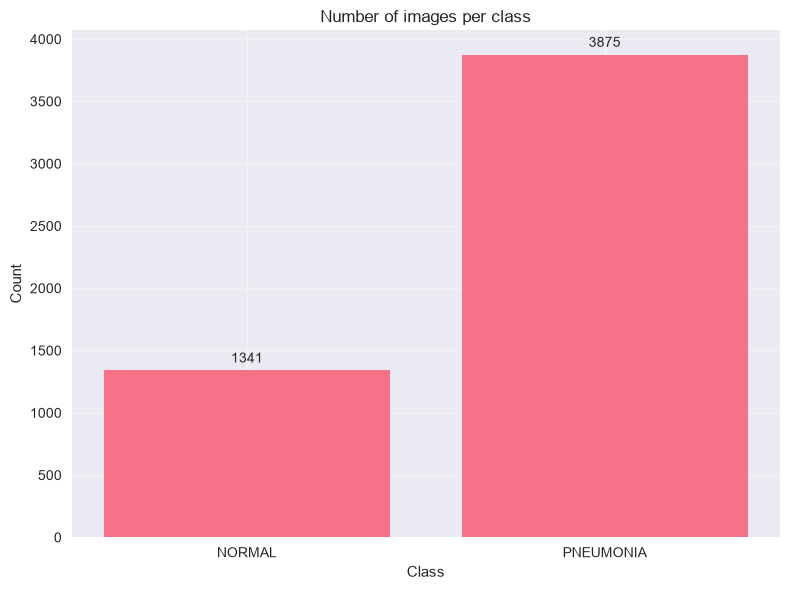

In [6]:
if os.path.exists(TRAIN_DIR):
    train_counts = count_images(TRAIN_DIR)
    print(f'Train set counts: {train_counts}')

    for class_name, count in train_counts.items():
        print(f'Class {class_name} has {count} images')
    plt.figure(figsize=(8, 6))
    classes = list(train_counts.keys())
    counts = list(train_counts.values())
    plt.bar(classes, counts)
    plt.xlabel('Class')
    plt.ylabel('Count')
    plt.grid(axis='y', alpha=0.3)
    plt.title('Number of images per class')
    for i, v in enumerate(counts):
        plt.text(i, v + max(counts)*0.01, str(v), ha='center', va='bottom')

    plt.tight_layout()
    plt.show()
else:
    print('Train set does not exist')

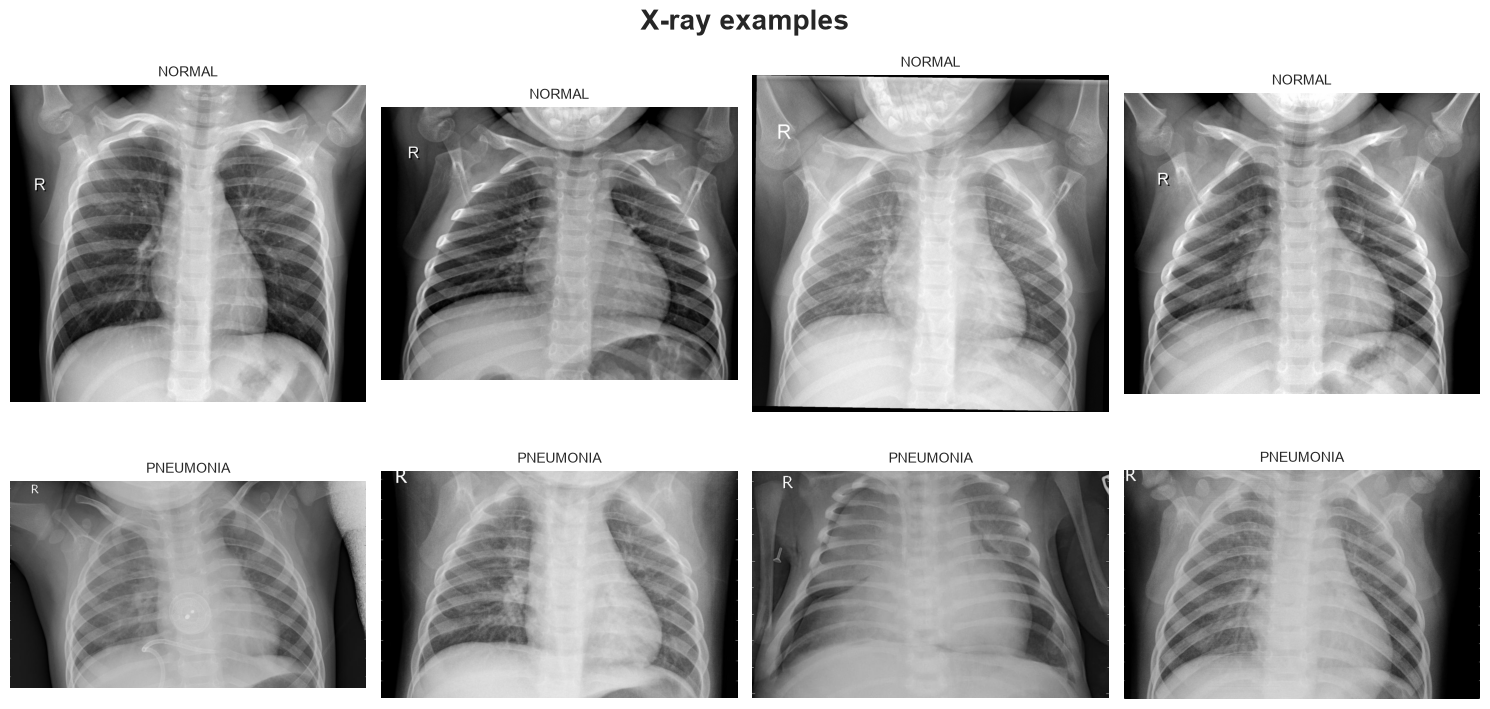

In [7]:
def visualize_samples(directory, num_samples=4):
    if not os.path.exists(directory):
        print(f'Directory {directory} does not exist')
        return

    fig, axes = plt.subplots(2, num_samples, figsize=(15, 8))
    fig.suptitle('X-ray examples', fontsize=20, fontweight='bold')


    classes = [d for d in os.listdir(directory) if os.path.isdir(os.path.join(directory, d))]

    for class_idx, class_name in enumerate(classes):
        class_dir = os.path.join(directory, class_name)
        image_files = [f for f in os.listdir(class_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        sample_files = np.random.choice(
            image_files,
            min(num_samples, len(image_files)),
            replace=False
        )

        for img_idx, img_file in enumerate(sample_files):
            img_path = os.path.join(class_dir, img_file)

            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            axes[class_idx, img_idx].imshow(img, cmap='gray')
            axes[class_idx, img_idx].set_title(class_name, fontsize=10)
            axes[class_idx, img_idx].axis('off')
    plt.tight_layout()
    plt.show()
if os.path.exists(TRAIN_DIR):
    visualize_samples(TRAIN_DIR)

# Data Augmentation

[Data Augmentation](https://www.ibm.com/think/topics/data-augmentation)

In [8]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=70,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.05,
    validation_split=VAL_SPLIT,
    fill_mode='nearest',
)

validation_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=VAL_SPLIT,
)

test_datagen = ImageDataGenerator(
    rescale=1./255,
)

# Neyron şəbəkənin arxitektura
1. Conv2D
2. MaxPooling2D
3. Batch Normalization
4. Dropout
5. Dense

[CNN](https://en.wikipedia.org/wiki/Convolutional_neural_network)

In [9]:
def create_cnn_model(input_shape=(IMG_SIZE, IMG_SIZE, IMG_CHANNELS)):
    model = Sequential([
        Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=input_shape),
        BatchNormalization(),
        Conv2D(32, (3, 3), activation='relu', padding='same'),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.25),

        Conv2D(64, (3, 3), activation='relu', padding='same', input_shape=input_shape),
        BatchNormalization(),
        Conv2D(64, (3, 3), activation='relu', padding='same'),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.25),

        Conv2D(128, (3, 3), activation='relu', padding='same', input_shape=input_shape),
        BatchNormalization(),
        Conv2D(128, (3, 3), activation='relu', padding='same'),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.25),

        Conv2D(256, (3, 3), activation='relu', padding='same', input_shape=input_shape),
        BatchNormalization(),
        Conv2D(256, (3, 3), activation='relu', padding='same'),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.25),

        Flatten(),

        Dense(512, activation='relu'),
        BatchNormalization(),
        Dropout(0.5),

        Dense(256, activation='relu'),
        BatchNormalization(),
        Dropout(0.5),

        Dense(1, activation='sigmoid'),
    ])
    return model

model = create_cnn_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    25,690,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 512)            │         2,04

 Total params: 26,999,457 (102.99 MB)

 Trainable params: 26,996,961 (102.99 MB)

 Non-trainable params: 2,496 (9.75 KB)

In [10]:
model.compile(
    optimizer= keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy', 'precision', 'recall'],
)

# Callbacks

1. Early stopping
2. ReduceLROnPlateau
3. ModelChekpoint

In [11]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, verbose=1, restore_best_weights=True),
    ReduceLROnPlateau( monitor='val_loss', factor=0.5, patience=3, verbose=1, min_lr=0.00001),
    ModelCheckpoint(filepath='models/best_model.h5', monitor='val_loss', save_best_only=True, verbose=1, mode='min'),
]

In [12]:
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=True,
    subset='training',
    seed=SEED,
    classes=['NORMAL', 'PNEUMONIA'],
    color_mode='rgb',
)

validation_generator = validation_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False,
    subset='validation',
    seed=SEED,
    classes=['NORMAL', 'PNEUMONIA'],
    color_mode='rgb',
)

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False,
    seed=SEED,
    classes=['NORMAL', 'PNEUMONIA'],
    color_mode='rgb',
)

Found 4173 images belonging to 2 classes.
Found 1043 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


In [13]:
print('Training started')
history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=validation_generator,
    callbacks=callbacks,
    verbose=1,
)
print('Training finished')


Training started
Epoch 1/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7580 - loss: 0.5990 - precision: 0.9394 - recall: 0.7206  
Epoch 1: val_loss improved from None to 0.93546, saving model to models/best_model.h5



Epoch 1: finished saving model to models/best_model.h5
131/131 ━━━━━━━━━━━━━━━━━━━━ 418s 3s/step - accuracy: 0.7580 - loss: 0.5990 - precision: 0.9394 - recall: 0.7206 - val_accuracy: 0.7430 - val_loss: 0.9355 - val_precision: 0.7430 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8526 - loss: 0.4007 - precision: 0.9694 - recall: 0.8277  
Epoch 2: val_loss did not improve from 0.93546
131/131 ━━━━━━━━━━━━━━━━━━━━ 412s 3s/step - accuracy: 0.8526 - loss: 0.4007 - precision: 0.9694 - recall: 0.8277 - val_accuracy: 0.7430 - val_loss: 1.0818 - val_precision: 0.7430 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 3/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8780 - loss: 0.3642 - precision: 0.9602 - recall: 0.8719  
Epoch 3: val_loss improved from 0.93546 to 0.92954, saving model to models/best_model.h5



Epoch 3: finished saving model to models/best_model.h5
131/131 ━━━━━━━━━━━━━━━━━━━━ 419s 3s/step - accuracy: 0.8780 - loss: 0.3642 - precision: 0.9602 - recall: 0.8719 - val_accuracy: 0.7430 - val_loss: 0.9295 - val_precision: 0.7430 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 4/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8972 - loss: 0.3045 - precision: 0.9671 - recall: 0.8919  
Epoch 4: val_loss improved from 0.92954 to 0.87717, saving model to models/best_model.h5



Epoch 4: finished saving model to models/best_model.h5
131/131 ━━━━━━━━━━━━━━━━━━━━ 412s 3s/step - accuracy: 0.8972 - loss: 0.3045 - precision: 0.9671 - recall: 0.8919 - val_accuracy: 0.7430 - val_loss: 0.8772 - val_precision: 0.7430 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 5/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9094 - loss: 0.2667 - precision: 0.9664 - recall: 0.9097  
Epoch 5: val_loss did not improve from 0.87717
131/131 ━━━━━━━━━━━━━━━━━━━━ 416s 3s/step - accuracy: 0.9094 - loss: 0.2667 - precision: 0.9664 - recall: 0.9097 - val_accuracy: 0.7430 - val_loss: 1.0127 - val_precision: 0.7430 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 6/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9147 - loss: 0.2531 - precision: 0.9620 - recall: 0.9216  
Epoch 6: val_loss did not improve from 0.87717
131/131 ━━━━━━━━━━━━━━━━━━━━ 413s 3s/step - accuracy: 0.9147 - loss: 0.2531 - precision: 0.9620 - recall: 0.9216 - val_accuracy: 0.7430 - val_loss


Epoch 7: finished saving model to models/best_model.h5
131/131 ━━━━━━━━━━━━━━━━━━━━ 409s 3s/step - accuracy: 0.9233 - loss: 0.2342 - precision: 0.9630 - recall: 0.9326 - val_accuracy: 0.7498 - val_loss: 0.7782 - val_precision: 0.7481 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 8/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9243 - loss: 0.2370 - precision: 0.9609 - recall: 0.9361  
Epoch 8: val_loss did not improve from 0.77815
131/131 ━━━━━━━━━━━━━━━━━━━━ 412s 3s/step - accuracy: 0.9243 - loss: 0.2370 - precision: 0.9609 - recall: 0.9361 - val_accuracy: 0.7430 - val_loss: 0.9449 - val_precision: 0.7430 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 9/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9315 - loss: 0.2176 - precision: 0.9616 - recall: 0.9455  
Epoch 9: val_loss did not improve from 0.77815
131/131 ━━━━━━━━━━━━━━━━━━━━ 405s 3s/step - accuracy: 0.9315 - loss: 0.2176 - precision: 0.9616 - recall: 0.9455 - val_accuracy: 0.7430 - val_loss

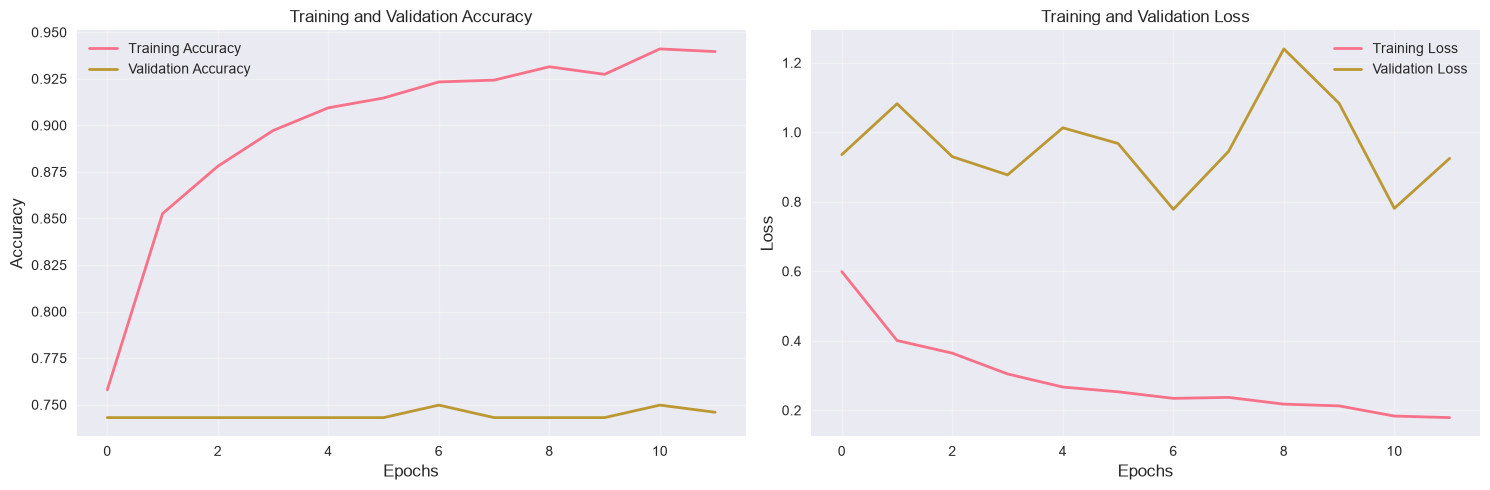

Model final metrics
Accuracy: 0.9396
Validation Accuracy: 0.7459
Loss: 0.1788
Validation Loss: 0.9246


In [14]:
from matplotlib import axes
def plot_training_history(history):
  fig, axes = plt.subplots(1, 2, figsize=(15, 5))

  # Accuracy
  axes[0].plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
  axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
  axes[0].set_title('Training and Validation Accuracy', fontsize=12)
  axes[0].set_xlabel('Epochs', fontsize=12)
  axes[0].set_ylabel('Accuracy', fontsize=12)
  axes[0].legend()
  axes[0].grid(True, alpha=0.3)

  # Loss
  axes[1].plot(history.history['loss'], label='Training Loss', linewidth=2)
  axes[1].plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
  axes[1].set_title('Training and Validation Loss', fontsize=12)
  axes[1].set_xlabel('Epochs', fontsize=12)
  axes[1].set_ylabel('Loss', fontsize=12)
  axes[1].legend()
  axes[1].grid(True, alpha=0.3)

  plt.tight_layout()
  plt.show()

  print("Model final metrics")
  print("=" * 50)
  print(f"Accuracy: {history.history['accuracy'][-1]:.4f}")
  print(f"Validation Accuracy: {history.history['val_accuracy'][-1]:.4f}")
  print(f"Loss: {history.history['loss'][-1]:.4f}")
  print(f"Validation Loss: {history.history['val_loss'][-1]:.4f}")

plot_training_history(history)

20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 683ms/step
NORMAL = 0
PNEUMONIA = 1


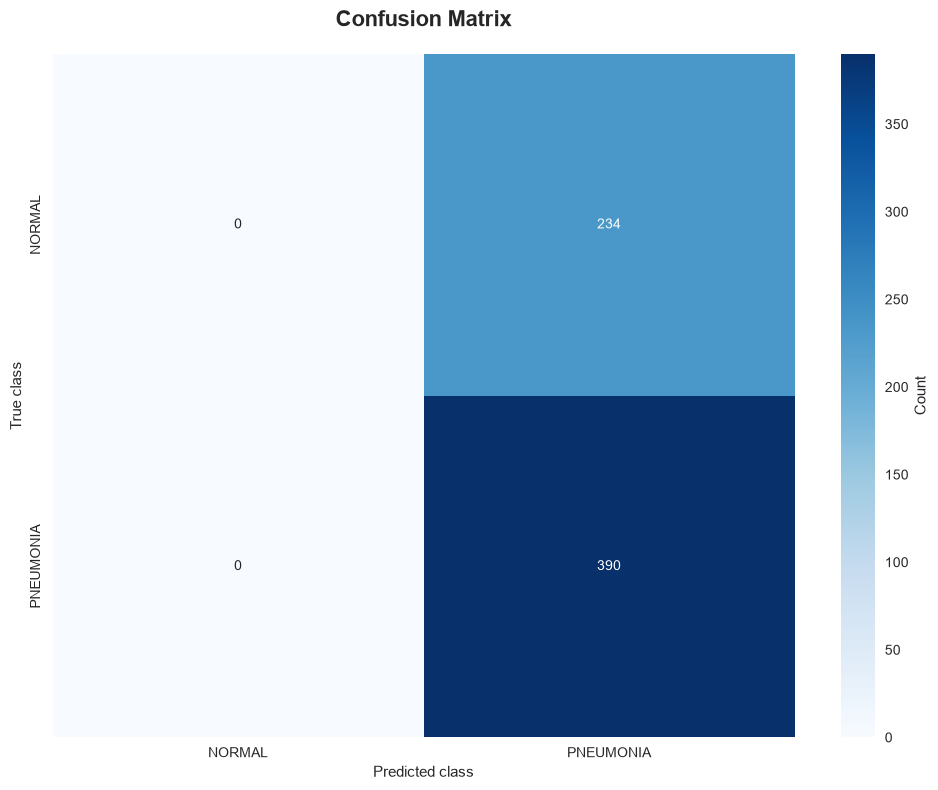

Confusion Matrix:
       Predicted
      NORMAL  PNEUMONIA
True  NORMAL: 0  234
      PNEUMONIA: 0  390
True positives (TP): 390 - true predicted PNEUMONIA
True negatives (TN): 0 - true predicted NORMAL
False positives (FP): 234 - false predicted PNEUMONIA
False negatives (FN): 0 - false predicted NORMAL
Accuracy: 0.6250
Precision NORMAL: 0.0000
Precision PNEUMONIA: 0.6250
Recall NORMAL: 0.0000
Recall PNEUMONIA: 1.0000
F1 score NORMAL: 0.0000
F1 score PNEUMONIA: 0.7692


In [15]:
test_generator.reset()
predictions = model.predict(test_generator)
predicted_classes = (predictions> 0.5).astype(int).flatten()
true_classes = test_generator.classes

class_names = list(test_generator.class_indices.keys())

print(f"{class_names[0]} = 0")
print(f"{class_names[1]} = 1")

cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, cbar_kws={'label': 'Count'})
plt.xlabel('Predicted class')
plt.ylabel('True class')
plt.title('Confusion Matrix', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print("       Predicted")
print(f"      {class_names[0]}  {class_names[1]}")
print(f"True  {class_names[0]}: {cm[0][0]}  {cm[0][1]}")
print(f"      {class_names[1]}: {cm[1][0]}  {cm[1][1]}")

TN = cm[0][0]
FP = cm[0][1]
FN = cm[1][0]
TP = cm[1][1]

print(f"True positives (TP): {TP} - true predicted {class_names[1]}")
print(f"True negatives (TN): {TN} - true predicted {class_names[0]}")
print(f"False positives (FP): {FP} - false predicted {class_names[1]}")
print(f"False negatives (FN): {FN} - false predicted {class_names[0]}")

accuracy = accuracy_score(true_classes, predicted_classes)
precision_0 = TN/(TN+FN) if TN+FN > 0 else 0
precision_1 = TP/(TP+FP) if TP+FP > 0 else 0
recall_0 = TN/(TN+FP) if TN+FP > 0 else 0
recall_1 = TP/(TP+FN) if TP+FN > 0 else 0

f1_0 = 2 * (precision_0 * recall_0) / (precision_0 + recall_0) if precision_0 + recall_0 > 0 else 0
f1_1 = 2 * (precision_1 * recall_1) / (precision_1 + recall_1) if precision_1 + recall_1 > 0 else 0

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision {class_names[0]}: {precision_0:.4f}")
print(f"Precision {class_names[1]}: {precision_1:.4f}")
print(f"Recall {class_names[0]}: {recall_0:.4f}")
print(f"Recall {class_names[1]}: {recall_1:.4f}")
print(f"F1 score {class_names[0]}: {f1_0:.4f}")
print(f"F1 score {class_names[1]}: {f1_1:.4f}")